# 03 · Exploratory Data Analysis
**Input:** `data/processed/master_clean.csv` · **Figures:** `figures/03_eda_*.png`

Structure (Python lab format): load and inspect → overview → univariate → bivariate and statistical tests → text-specific analysis → correlations → findings.
After every result, a short note says **what we see** and **why this technique**.

All statistics that could influence modeling choices (e.g. the length cutoff) are computed on **training rows only**, so nothing is learned from the test set.

In [1]:
# Works both locally (repo root or notebooks/) and in Colab after cloning the repo.
import os, sys
from pathlib import Path
if Path("notebooks").is_dir():
    ROOT = Path(".").resolve()
elif Path("../notebooks").is_dir():
    ROOT = Path("..").resolve()
else:  # Colab: the repository is cloned into /content first
    ROOT = Path("/content/tunisian-sentiment")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print("Repo root found:", ROOT.name)

Repo root found: tunisian-sentiment


In [2]:
# In Colab, run once: !pip install arabic-reshaper python-bidi
import re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from src.plot_style import setup, COLORS, INK, MUTED, ar, subtitle, label_bars

setup()
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
def save(fig, name):
    fig.savefig(FIG / f"03_eda_{name}.png"); plt.show()

df = pd.read_csv(ROOT / "data/processed/master_clean.csv", keep_default_na=False)
for c in ["has_emoji", "has_arabizi_digits", "has_elongation"]:
    df[c] = df[c].astype(str).eq("True")
train = df[df.split == "train"]
tsac = df[df.source == "tsac"]

## 1. Shape, types, missing values

In [3]:
print("Rows, columns:", df.shape)
df.info()
print("\nMissing or empty values per column:\n", (df.isna() | df.astype(str).eq("")).sum())

Rows, columns: (111531, 11)
<class 'pandas.DataFrame'>
RangeIndex: 111531 entries, 0 to 111530
Data columns (total 11 columns):
 #   Column              Non-Null Count   Dtype
---  ------              --------------   -----
 0   id                  111531 non-null  str  
 1   text                111531 non-null  str  
 2   label               111531 non-null  str  
 3   source              111531 non-null  str  
 4   split               111531 non-null  str  
 5   script              111531 non-null  str  
 6   n_chars             111531 non-null  int64
 7   n_words             111531 non-null  int64
 8   has_emoji           111531 non-null  bool 
 9   has_arabizi_digits  111531 non-null  bool 
 10  has_elongation      111531 non-null  bool 
dtypes: bool(3), int64(2), str(6)
memory usage: 7.1 MB

Missing or empty values per column:
 id                    0
text                  0
label                 0
source                0
split                 0
script                0
n_chars    

In [4]:
print(pd.crosstab([df.source, df.split], df.script, margins=True, margins_name="total"))
df[["n_chars", "n_words"]].describe().round(1)

script        arabic  arabizi   total
source split                         
tsac   test     1482     1707    3189
       train    5506     6437   11943
tunizi train       0    96399   96399
total           6988   104543  111531


,n_chars,n_words
count,111531.0,111531.0
mean,55.6,9.6
std,71.4,11.8
min,1.0,1.0
25%,20.0,3.0
50%,34.0,6.0
75%,63.0,11.0
max,6270.0,208.0


**What we see:** 111,531 comments and 11 columns, with no missing values left after cleaning. Arabizi dominates (about 94%), because TUNIZI is Arabizi-only. Arabic script exists only in TSAC.
**Why:** `.shape`, `.info()` and the missing-value count are the basic checks that the cleaning left a consistent table.

## 2. Label balance by source and by script

label             neg    pos
source script               
tsac   arabic    3845   3143
       arabizi   3480   4664
tunizi arabizi  43723  52676
label            neg   pos
source script             
tsac   arabic   55.0  45.0
       arabizi  42.7  57.3
tunizi arabizi  45.4  54.6


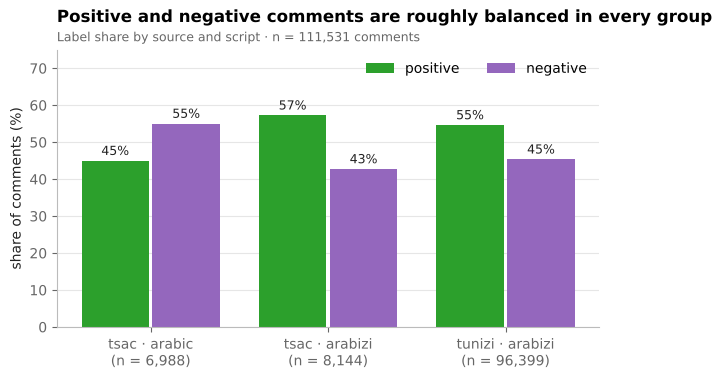

In [5]:
bal = pd.crosstab([df.source, df.script], df.label, normalize="index").mul(100)
counts = pd.crosstab([df.source, df.script], df.label)
print(counts); print(bal.round(1))

fig, ax = plt.subplots(figsize=(7, 3.6))
groups = [f"{s} · {sc}" for s, sc in bal.index]
x = np.arange(len(groups)); w = 0.38
b1 = ax.bar(x - w/2 - 0.01, bal["pos"], w, color=COLORS["pos"], label="positive")
b2 = ax.bar(x + w/2 + 0.01, bal["neg"], w, color=COLORS["neg"], label="negative")
ax.bar_label(b1, fmt="%.0f%%", padding=2, color=INK, fontsize=9)
ax.bar_label(b2, fmt="%.0f%%", padding=2, color=INK, fontsize=9)
ax.set_xticks(x, [f"{g}\n(n = {counts.loc[i].sum():,})" for g, i in zip(groups, bal.index)])
ax.set_ylabel("share of comments (%)"); ax.set_ylim(0, 75); ax.grid(axis="x", visible=False)
ax.set_title("Positive and negative comments are roughly balanced in every group")
subtitle(ax, f"Label share by source and script · n = {len(df):,} comments")
ax.legend(loc="upper right", ncol=2)
save(fig, "label_balance")

**What we see:** No group falls below roughly 45% for either class, so the classes are close to balanced. Still, the balance differs by script (next section).
**Why:** Class balance decides the metric. With near-balanced classes accuracy is readable, but we keep **macro-F1** as the main metric because it weighs both classes equally and does not reward always predicting the larger class.

## 3. Is sentiment linked to script? Chi-square test of independence (TSAC)
Both scripts come from the same TSAC pages, so if script and label were unrelated, both scripts would have the same positive share.

- **H0:** script and sentiment are independent in TSAC.
- **H1:** the positive/negative share depends on the script.
- **Why chi-square:** both variables are categorical (2 × 2 table) and every expected cell count is far above 5, so the chi-square approximation is valid. **Cramér's V** gives the effect size, because with ~15,000 rows even a tiny difference can be "significant".

In [6]:
ct = pd.crosstab(tsac.script, tsac.label)
chi2, p, dof, expected = stats.chi2_contingency(ct, correction=False)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
print("Observed:\n", ct, "\n\nExpected if independent:\n", pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(0))
print("\nRow percentages:\n", pd.crosstab(tsac.script, tsac.label, normalize="index").mul(100).round(1))
print(f"\nchi2 = {chi2:.1f}, dof = {dof}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}, min expected = {expected.min():.0f}")

ar_test = df[(df.source == "tsac") & (df.split == "test") & (df.script == "arabic")]
majority = ar_test.label.value_counts(normalize=True)
print(f"\nArabic-script TEST set: n = {len(ar_test)}, {majority.idxmax()} = {majority.max():.1%} -> accuracy of always predicting '{majority.idxmax()}'")

Observed:
 label     neg   pos
script             
arabic   3845  3143
arabizi  3480  4664 

Expected if independent:
 label       neg     pos
script                 
arabic   3383.0  3605.0
arabizi  3942.0  4202.0

Row percentages:
 label     neg   pos
script             
arabic   55.0  45.0
arabizi  42.7  57.3

chi2 = 227.5, dof = 1, p = 2.06e-51, Cramér's V = 0.123, min expected = 3383

Arabic-script TEST set: n = 1482, neg = 57.5% -> accuracy of always predicting 'neg'


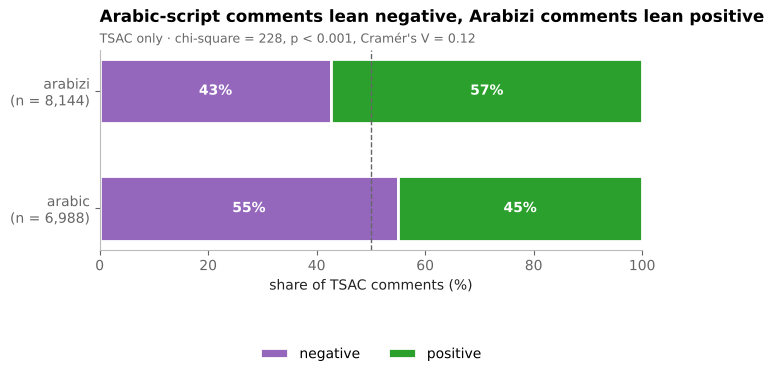

In [7]:
pct = pd.crosstab(tsac.script, tsac.label, normalize="index").mul(100)[["neg", "pos"]]
fig, ax = plt.subplots(figsize=(7, 2.6))
left = np.zeros(len(pct))
for lab in ["neg", "pos"]:
    bars = ax.barh(pct.index, pct[lab], left=left, color=COLORS[lab], height=0.55,
                   label="negative" if lab == "neg" else "positive", edgecolor="white", linewidth=2)
    for b, v, l0 in zip(bars, pct[lab], left):
        ax.text(l0 + v / 2, b.get_y() + b.get_height() / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += pct[lab].values
ax.axvline(50, color=MUTED, lw=1, ls="--")
ax.set_xlim(0, 100); ax.set_xlabel("share of TSAC comments (%)"); ax.grid(visible=False)
ax.set_yticks(range(len(pct)), [f"{s}\n(n = {ct.loc[s].sum():,})" for s in pct.index])
ax.set_title("Arabic-script comments lean negative, Arabizi comments lean positive")
subtitle(ax, f"TSAC only · chi-square = {chi2:.0f}, p < 0.001, Cramér's V = {cramers_v:.2f}")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.62), ncol=2)
save(fig, "script_vs_label")

**Result:** χ² = 227.5 (1 degree of freedom), p ≈ 2 × 10⁻⁵¹, Cramér's V = 0.12. We **reject H0**: in TSAC, Arabic-script comments are 55% negative and Arabizi comments 57% positive. The smallest expected count (3,383) is far above 5, so the test is valid.

**Interpretation:** the link is real but **weak** (V = 0.12): script alone does not determine sentiment. It still matters for us in two ways:
1. A model could partly "guess" sentiment from the script instead of the words. That's why **every result is reported separately per script**.
2. On our Arabic-script **test set** (1,482 comments), always predicting "negative" already gets **57.5% accuracy**. This is the floor every model must beat (sanity criterion in our success criteria).

## 4. Comment length
Lengths are strongly right-skewed (many very short comments, a few very long ones, up to 208 words), so we summarize with the **median and percentiles** rather than the mean, and the histogram groups the long tail into a last "40 or more" bin.

script         arabic   arabizi
n_words count  6988.0  104543.0
        mean      9.5       9.6
        std      11.4      11.8
        min       1.0       1.0
        50%       6.0       6.0
        95%      28.0      30.0
        max     208.0     199.0
n_chars count  6988.0  104543.0
        mean     49.9      56.0
        std      60.2      72.1
        min       2.0       1.0
        50%      32.0      34.0
        95%     146.0     173.0
        max    1024.0    6270.0

95th percentile of n_chars on TRAIN rows: 172 characters


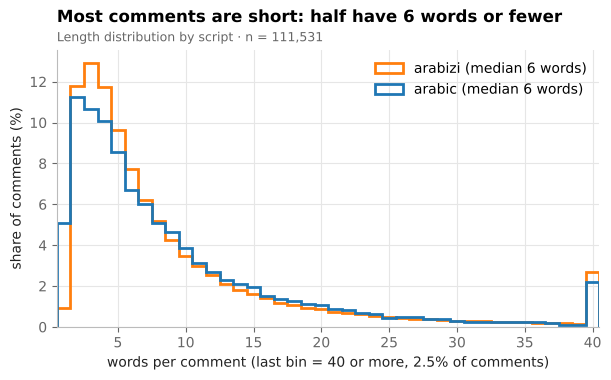

In [8]:
print(df.groupby("script")[["n_words", "n_chars"]].describe(percentiles=[.5, .95]).round(1).T)
p95_chars = int(np.percentile(train.n_chars, 95))
print(f"\n95th percentile of n_chars on TRAIN rows: {p95_chars} characters")

fig, ax = plt.subplots(figsize=(7, 3.6))
CAP = 40
bins = np.arange(0.5, CAP + 1.5, 1)
for s in ["arabizi", "arabic"]:
    d = df[df.script == s].n_words
    w = np.full(len(d), 100 / len(d))
    ax.hist(d.clip(upper=CAP), bins=bins, weights=w, histtype="step", lw=2, color=COLORS[s],
            label=f"{s} (median {d.median():.0f} words)")
over = (df.n_words > CAP).mean()
ax.set_xlabel(f"words per comment (last bin = {CAP} or more, {over:.1%} of comments)")
ax.set_ylabel("share of comments (%)"); ax.set_xlim(0.5, CAP + 0.5)
ax.set_title(f"Most comments are short: half have {df.n_words.median():.0f} words or fewer")
subtitle(ax, f"Length distribution by script · n = {len(df):,}")
ax.legend()
save(fig, "length_by_script")

**Second hypothesis test: are negative comments longer than positive ones?**
Lengths are not normally distributed (heavy right tail), so a t-test is not appropriate. The **Mann-Whitney U test** compares the two distributions without assuming normality. Tested per script, because the scripts differ in length.
- **H0:** positive and negative comments have the same length distribution.

 script      n  median_pos  median_neg            U      p_value  effect_neg_longer
 arabic   6988         6.0         7.0    6507999.0 2.630909e-08              0.077
arabizi 104543         5.0         7.0 1690100487.5 0.000000e+00              0.249


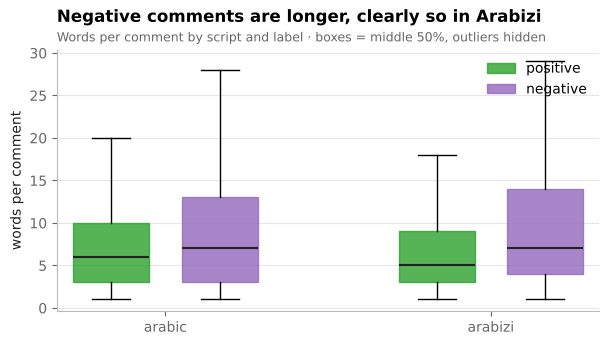

In [9]:
rows = []
for s in ["arabic", "arabizi"]:
    d = df[df.script == s]
    pos, neg = d[d.label == "pos"].n_words, d[d.label == "neg"].n_words
    u, p_mw = stats.mannwhitneyu(neg, pos, alternative="two-sided")
    r_rb = 2 * u / (len(neg) * len(pos)) - 1       # rank-biserial effect size: > 0 means negative comments are longer
    rows.append({"script": s, "n": len(d), "median_pos": pos.median(), "median_neg": neg.median(),
                 "U": u, "p_value": p_mw, "effect_neg_longer": round(r_rb, 3)})
mw = pd.DataFrame(rows)
print(mw.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.4))
data, pos_, cols = [], [], []
for i, s in enumerate(["arabic", "arabizi"]):
    for j, lab in enumerate(["pos", "neg"]):
        data.append(df[(df.script == s) & (df.label == lab)].n_words); pos_.append(i * 3 + j); cols.append(COLORS[lab])
bp = ax.boxplot(data, positions=pos_, widths=0.7, patch_artist=True, showfliers=False,
                medianprops=dict(color=INK, lw=1.5))
for patch, c in zip(bp["boxes"], cols):
    patch.set_facecolor(c); patch.set_alpha(0.8); patch.set_edgecolor(c)
ax.set_xticks([0.5, 3.5], ["arabic", "arabizi"]); ax.set_ylabel("words per comment"); ax.grid(axis="x", visible=False)
ax.legend([bp["boxes"][0], bp["boxes"][1]], ["positive", "negative"], loc="upper right")
ax.set_title("Negative comments are longer, clearly so in Arabizi")
subtitle(ax, "Words per comment by script and label · boxes = middle 50%, outliers hidden")
save(fig, "length_by_label")

**Result:** we reject H0 for both scripts (Arabic p ≈ 3 × 10⁻⁸; Arabizi p < 10⁻³⁰⁰). Negative comments are longer: median 7 words vs 6 (Arabic) and 7 vs 5 (Arabizi).

**Interpretation:** the **effect size** matters more than the p-value here, because with 100,000 rows almost any difference is "significant". The rank-biserial effect is **small in Arabizi (0.25)** and **negligible in Arabic (0.08)**. People complaining tend to write more. Length is a weak extra signal; it doesn't replace the words. The heatmap below confirms it (r = −0.18 between length and positive).

## 5. Words that separate positive from negative, per script
Raw top-word lists are dominated by function words ("w", "ya", "و", "في") that appear in both classes. Instead we rank words by the **log-odds ratio** between positive and negative comments (with +1 smoothing, words seen at least 30 times). This highlights the words that **distinguish** the classes. Computed on **training rows only**.

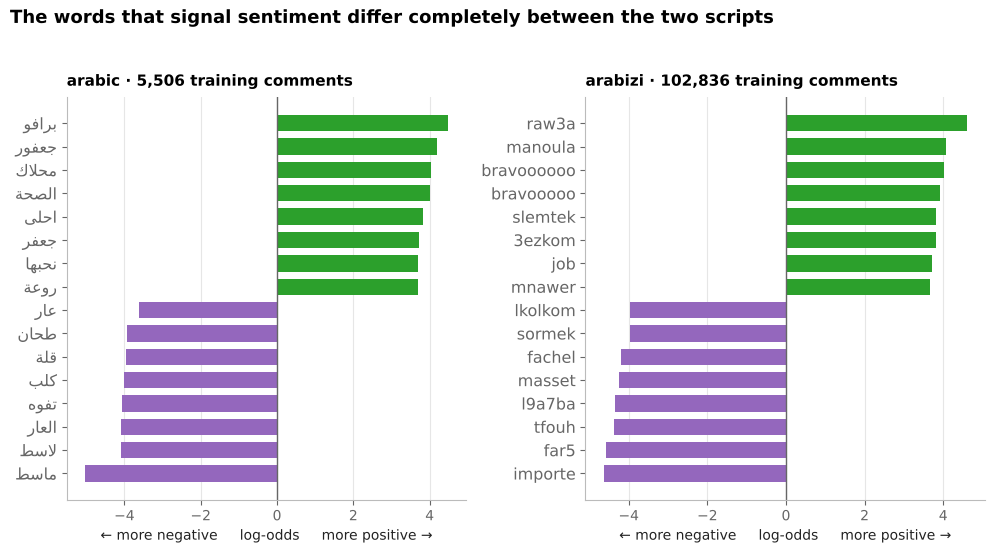

arabic -> neg: ['ماسط', 'لاسط', 'العار', 'تفوه', 'كلب', 'قلة', 'طحان', 'عار'] | pos: ['روعة', 'نحبها', 'جعفر', 'احلى', 'الصحة', 'محلاك', 'جعفور', 'برافو']
arabizi -> neg: ['importe', 'far5', 'tfouh', 'l9a7ba', 'masset', 'fachel', 'sormek', 'lkolkom'] | pos: ['mnawer', 'job', '3ezkom', 'slemtek', 'bravooooo', 'bravoooooo', 'manoula', 'raw3a']


In [10]:
TOKEN = re.compile(r"[\w']+", re.UNICODE)
def tokens(s): return [t.lower() for t in TOKEN.findall(s) if len(t) >= 2 and not t.isdigit()]

def log_odds(sub, min_count=30, k=10):
    cp, cn = Counter(), Counter()
    for t, l in zip(sub.text, sub.label):
        (cp if l == "pos" else cn).update(set(tokens(t)))
    vocab = [w for w in set(cp) | set(cn) if cp[w] + cn[w] >= min_count]
    npos, nneg = (sub.label == "pos").sum(), (sub.label == "neg").sum()
    lo = pd.Series({w: np.log((cp[w] + 1) / (npos + 1)) - np.log((cn[w] + 1) / (nneg + 1)) for w in vocab})
    return lo.sort_values(), cp, cn

fig, axes = plt.subplots(1, 2, figsize=(10, 5.6))
top_words = {}
for ax, s in zip(axes, ["arabic", "arabizi"]):
    lo, cp, cn = log_odds(train[train.script == s])
    sel = pd.concat([lo.head(8), lo.tail(8)])
    top_words[s] = sel
    labels = [ar(w) if s == "arabic" else w for w in sel.index]
    ax.barh(range(len(sel)), sel.values, color=[COLORS["pos"] if v > 0 else COLORS["neg"] for v in sel.values], height=0.7)
    ax.set_yticks(range(len(sel)), labels, fontsize=11.5); ax.axvline(0, color=MUTED, lw=1)
    ax.set_xlabel("← more negative     log-odds     more positive →"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{s} · {(train.script == s).sum():,} training comments", fontsize=11, pad=8)
fig.suptitle("The words that signal sentiment differ completely between the two scripts", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout(rect=(0, 0, 1, 0.95))
save(fig, "distinctive_words")
for s, sel in top_words.items(): print(s, "-> neg:", list(sel.index[:8]), "| pos:", list(sel.index[-8:]))

**What we see:** the most positive words are praise (برافو / bravo, روعة / raw3a, محلاك, 3ezkom, slemtek) and the most negative are insults and contempt (ماسط / masset, تفوه / tfouh, العار, fachel). **The same words appear on both sides, in different scripts:** ماسط ↔ masset, تفوه ↔ tfouh, روعة ↔ raw3a.

**Why this matters:** to a computer, ماسط and masset share no character, so a model trained on Arabizi has never "seen" the Arabic words it needs. This is exactly the gap the cross-script conversion targets. It also shows elongations (bravooooo, bravoooooooo) splitting one word into several, which motivates collapsing repeated letters.

## 6. Arabizi digits: numbers used as letters
In Arabizi, digits stand for Arabic sounds with no Latin letter: 3 = ع, 7 = ح, 5 = خ, 9 = ق, 2 = ء, 8 = غ. We count a digit only when it **touches a Latin letter** (`3aychek` counts, `2016` does not).

3    48.4
7    29.9
9    21.7
5    17.0
2     2.4
8     2.0
dtype: float64


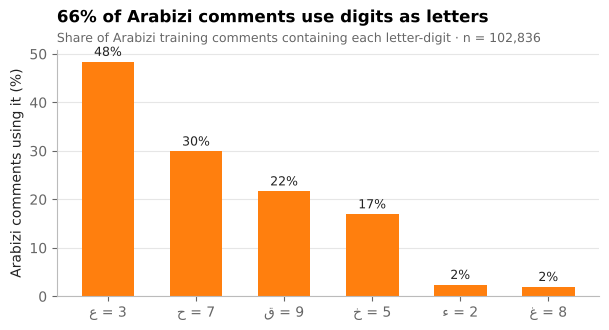

In [11]:
azz = train[train.script == "arabizi"]
digit_share = {d: azz.text.str.contains(rf"(?<=[A-Za-z]){d}|{d}(?=[A-Za-z])").mean() * 100 for d in "235789"}
digit_share = pd.Series(digit_share).sort_values(ascending=False)
names = {"3": "3 = ع", "7": "7 = ح", "5": "5 = خ", "9": "9 = ق", "2": "2 = ء", "8": "8 = غ"}
print(digit_share.round(1))

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar([ar(names[d]) for d in digit_share.index], digit_share.values, color=COLORS["arabizi"], width=0.6)
ax.bar_label(bars, fmt="%.0f%%", padding=2, color=INK, fontsize=9)
ax.set_ylabel("Arabizi comments using it (%)"); ax.grid(axis="x", visible=False)
ax.set_title(f"{azz.has_arabizi_digits.mean():.0%} of Arabizi comments use digits as letters")
subtitle(ax, f"Share of Arabizi training comments containing each letter-digit · n = {len(azz):,}")
save(fig, "arabizi_digits")

**What we see:** 66% of Arabizi comments use digits as letters; 3 (ع) appears in almost half of them, then 7 (ح), 9 (ق) and 5 (خ). 2 and 8 are rare.

**Why this matters:** these digits are **letters**, not numbers. Cleaning must not remove them, and the conversion maps ع → 3, ح → 7, ق → 9, خ → 5 so that Arabic-script words land on the same symbols Arabizi writers already use.

## 7. Noise: elongations and emoji by script

         has_elongation  has_emoji
script                            
arabic             22.5        4.3
arabizi            18.3        0.3

Emoji share by source:
 source
tsac      4.3
tunizi    0.0
Name: has_emoji, dtype: float64


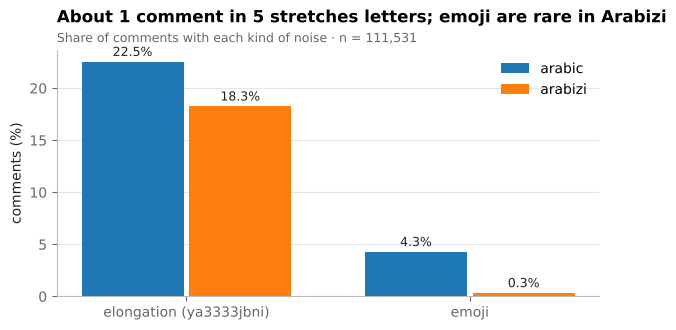

In [12]:
noise = df.groupby("script")[["has_elongation", "has_emoji"]].mean().mul(100)
print(noise.round(1))
print("\nEmoji share by source:\n", df.groupby("source").has_emoji.mean().mul(100).round(1))

fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(2); w = 0.36
for i, s in enumerate(["arabic", "arabizi"]):
    bars = ax.bar(x + (i - 0.5) * (w + 0.02), noise.loc[s].values, w, color=COLORS[s], label=s)
    ax.bar_label(bars, fmt="%.1f%%", padding=2, color=INK, fontsize=9)
ax.set_xticks(x, ["elongation (ya3333jbni)", "emoji"]); ax.set_ylabel("comments (%)"); ax.grid(axis="x", visible=False)
ax.set_title("About 1 comment in 5 stretches letters; emoji are rare in Arabizi")
subtitle(ax, f"Share of comments with each kind of noise · n = {len(df):,}")
ax.legend()
save(fig, "noise_by_script")

**What we see:** about 1 comment in 5 stretches letters (22.5% Arabic, 18.3% Arabizi). Emoji appear in 4.3% of TSAC comments but in **0.0% of TUNIZI**: its authors appear to have removed emoji from the dataset.

**Why this matters:** elongations multiply spellings of the same word, so normalization collapses runs of 3+ identical characters. Emoji are a TSAC-only signal, so a model trained mostly on TUNIZI will barely learn from them. We keep them (they are identical in both scripts) but **list this as a limitation**.

## 8. Correlations between the numeric features, label and script
All variables are numeric or binary (label: positive = 1; script: Arabic = 1), so **Pearson correlation** is used; between two binary variables it equals the phi coefficient, and between a binary and a numeric variable it is the point-biserial correlation. **Spearman** is shown for the two length columns because they are skewed.
Computed on training rows.

Spearman n_chars vs n_words: 0.964


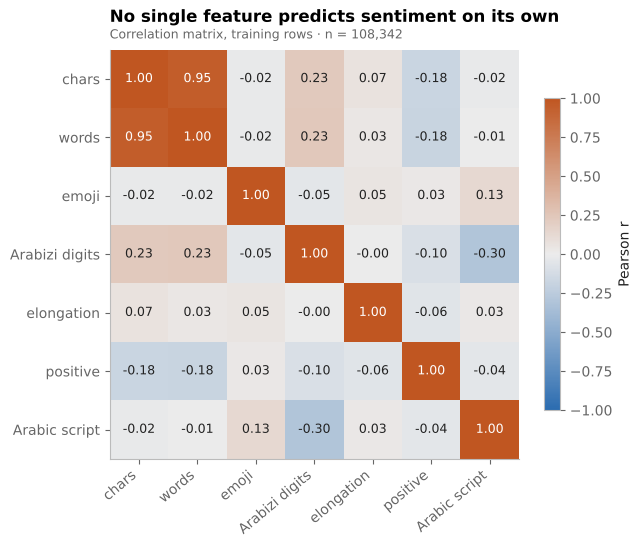

,n_chars,n_words,has_emoji,has_arabizi_digits,has_elongation,label_pos,script_arabic
n_chars,1.000,0.952,-0.018,0.234,0.068,-0.179,-0.022
n_words,0.952,1.000,-0.016,0.235,0.033,-0.182,-0.006
has_emoji,-0.018,-0.016,1.000,-0.046,0.048,0.028,0.129
has_arabizi_digits,0.234,0.235,-0.046,1.000,-0.004,-0.102,-0.299
has_elongation,0.068,0.033,0.048,-0.004,1.000,-0.056,0.027
label_pos,-0.179,-0.182,0.028,-0.102,-0.056,1.000,-0.041
script_arabic,-0.022,-0.006,0.129,-0.299,0.027,-0.041,1.000


In [13]:
num = train.assign(label_pos=(train.label == "pos").astype(int),
                   script_arabic=(train.script == "arabic").astype(int))
cols = ["n_chars", "n_words", "has_emoji", "has_arabizi_digits", "has_elongation", "label_pos", "script_arabic"]
corr = num[cols].astype(float).corr(method="pearson")
print("Spearman n_chars vs n_words:", round(stats.spearmanr(num.n_chars, num.n_words)[0], 3))

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("div", ["#2b6cb0", "#ececec", "#c05621"])
fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
pretty = ["chars", "words", "emoji", "Arabizi digits", "elongation", "positive", "Arabic script"]
ax.set_xticks(range(len(cols)), pretty, rotation=40, ha="right"); ax.set_yticks(range(len(cols)), pretty)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if abs(v) > 0.6 else INK)
ax.grid(visible=False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
ax.set_title("No single feature predicts sentiment on its own")
subtitle(ax, f"Correlation matrix, training rows · n = {len(num):,}")
save(fig, "correlation_heatmap")
corr.round(3)

**What we see:**
- `chars` and `words` are almost the same information (r = 0.95; Spearman 0.96). Only one of them should be kept as a feature.
- The strongest link with sentiment is length (r = −0.18): longer comments lean negative, matching the Mann-Whitney test.
- `Arabizi digits` vs `Arabic script` is −0.30 by construction (Arabic-script text has no Arabizi digits).
- Emoji and elongation barely relate to sentiment (|r| ≤ 0.06).

**Interpretation:** no single numeric feature predicts sentiment. The signal is in the **words**, which is why the main features are character n-grams of the text (feature engineering notebook), not these summary columns.

## 9. Findings and what they change in the preparation

| # | Finding (with number) | What it changes in data preparation |
|---|---|---|
| 1 | Script and sentiment are linked (χ² = 227.5, p < 0.001) but weakly (Cramér's V = 0.12); the Arabic test set is 57.5% negative | Report every result **per script**; 57.5% is the accuracy floor; main metric **macro-F1** |
| 2 | Sentiment words are the same in both scripts but share no characters (ماسط ↔ masset, تفوه ↔ tfouh) | Motivates the **cross-script conversion** to one shared form |
| 3 | 66% of Arabizi comments use digits as letters (3 = ع in 48%) | Keep digits; map ع ح ق خ to 3 7 9 5 in the conversion |
| 4 | About 20% of comments contain elongations (bravooooo) | Collapse repeated characters during normalization |
| 5 | Half the comments have 6 words or fewer; 95% of training comments have ≤ 172 characters | Character-level features (words are too few and too variable); cut neural inputs at **172 characters** |
| 6 | chars and words are 95% correlated; length is weakly linked to sentiment (r = −0.18) | Keep one length feature at most; rely on text n-grams |
| 7 | Emoji: 4.3% of TSAC, 0% of TUNIZI | Keep emoji as tokens, but state the limitation |